# Análise Exploratória de Dados - AED

### Base a ser utilizada: livros.csv

## 1. Importação das bibliotecas

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## 2. Carregar a base de dados

In [4]:
arquivo = Path("livros.csv")

if not arquivo.exists():
    raise FileNotFoundError(
        "Arquivo não encontrado. Certifique-se de que o arquivo está no diretório correto."
    )

df_original = pd.read_csv(arquivo)
df = df_original.copy()

df.head()

,id_livro,titulo,autor,categoria,ano_publicacao,paginas,avaliacao,qtd_avaliacoes,preco,idioma
0,1,Extraordinário,R. J. Palacio,Drama,"2012,0",320,"4,8",9800,"49,9",Português
1,2,Como Eu Era Antes de Você,Jojo Moyes,Romance,"2012,0",320,"4,7",11200,"49,9",Português
2,3,É Assim que Acaba,Colleen Hoover,Romance,"2018,0",368,"4,7",12500,"49,9",Português
3,4,É Assim que Começa,Colleen Hoover,Romance,"2022,0",336,"4,8",11200,"54,9",Português
4,5,Verity,Colleen Hoover,Suspense,"2018,0",320,"4,7",9800,"49,9",Português


In [5]:
df.shape

(50, 10)

## 3. Entendendo a estrutura de Dados

In [6]:
print(f"linhas: {df.shape[0]}")
print(f"colunas: {df.shape[1]}")
print(f"Nome das colunas: {df.columns}")

linhas: 50
colunas: 10
Nome das colunas: Index(['id_livro', 'titulo', 'autor', 'categoria', 'ano_publicacao', 'paginas',
       'avaliacao', 'qtd_avaliacoes', 'preco', 'idioma'],
      dtype='object')


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id_livro        50 non-null     int64 
 1   titulo          50 non-null     object
 2   autor           50 non-null     object
 3   categoria       50 non-null     object
 4   ano_publicacao  48 non-null     object
 5   paginas         50 non-null     int64 
 6   avaliacao       49 non-null     object
 7   qtd_avaliacoes  50 non-null     int64 
 8   preco           49 non-null     object
 9   idioma          50 non-null     object
dtypes: int64(3), object(7)
memory usage: 4.0+ KB


In [8]:
df.describe(include="all")

,id_livro,titulo,autor,categoria,ano_publicacao,paginas,avaliacao,qtd_avaliacoes,preco,idioma
count,50.00000,50,50,50,48,50.000000,49,50.000000,49,50
unique,NaN,50,40,12,18,NaN,11,NaN,20,2
top,NaN,Extraordinário,Colleen Hoover,Drama,"2018,0",NaN,"4,7",NaN,"49,9",Português
freq,NaN,1,3,10,9,NaN,16,NaN,10,49
mean,25.50000,NaN,NaN,NaN,NaN,361.160000,NaN,7098.000000,NaN,NaN
std,14.57738,NaN,NaN,NaN,NaN,124.477087,NaN,3184.111705,NaN,NaN
min,1.00000,NaN,NaN,NaN,NaN,144.000000,NaN,0.000000,NaN,NaN
25%,13.25000,NaN,NaN,NaN,NaN,274.000000,NaN,4350.000000,NaN,NaN
50%,25.50000,NaN,NaN,NaN,NaN,352.000000,NaN,6500.000000,NaN,NaN
75%,37.75000,NaN,NaN,NaN,NaN,408.000000,NaN,9800.000000,NaN,NaN


## 4. Investigar duplicatas, ausentes, categóricos

In [9]:
# Quantidade de valores ausentes por coluna

df_resumo_ausentes = pd.DataFrame({
    "ausentes": df.isna().sum(),
    "percentual": (df.isna().mean() * 100).round(2)
}).sort_values(by="ausentes", ascending=False)

df_resumo_ausentes

,ausentes,percentual
ano_publicacao,2,4.0
avaliacao,1,2.0
preco,1,2.0
id_livro,0,0.0
titulo,0,0.0
autor,0,0.0
paginas,0,0.0
categoria,0,0.0
qtd_avaliacoes,0,0.0
idioma,0,0.0


In [10]:
# Linhas duplicadas
print(f"Linhas completamente duplicadas: {df.duplicated().sum()}")
print("IDs duplicados:", df["id_livro"].duplicated().sum())



# Verificar a categorias e idiomas distintos
print("\nCategorias encontradas:")
display(df["categoria"].value_counts(dropna=False))

print("\nIdiomas encontrados:")
display(df["idioma"].value_counts(dropna=False))


Linhas completamente duplicadas: 0
IDs duplicados: 0

Categorias encontradas:


categoria
Drama                10
Romance               8
Suspense              5
Fantasia              5
Autoajuda             5
Financeiro            4
História              4
Ficção Científica     4
Ficção                2
suspense              1
AUTOAJUDA             1
Tecnologia            1
Name: count, dtype: int64


Idiomas encontrados:


idioma
Português    49
português     1
Name: count, dtype: int64

## 5. Preparar campos numéricos para análise

In [11]:
# Padronização de campos textuais categóricos
df["categoria"] = df["categoria"].astype("string").str.strip().str.title()
df["idioma"] = df["idioma"].astype("string").str.strip().str.title()

# Converter textos com vírgula decimal para números
def converter_decimal(serie):
    texto = serie.astype("string").str.strip()
    texto = texto.str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")

df["avaliacao"] = converter_decimal(df["avaliacao"])
df["preco"] = converter_decimal(df["preco"])

# Normalizar o ano: "2018,0" -> 2018; valores inválidos viram ausentes
ano_texto = df["ano_publicacao"].astype("string").str.strip()
ano_texto = ano_texto.str.replace(",", ".", regex=False)
df["ano_publicacao"] = pd.to_numeric(ano_texto, errors="coerce")

# Só convertemos para inteiro anulável depois da conversão numérica
df["ano_publicacao"] = df["ano_publicacao"].round().astype("Int64")

df.dtypes

id_livro                   int64
titulo                    object
autor                     object
categoria         string[python]
ano_publicacao             Int64
paginas                    int64
avaliacao                Float64
qtd_avaliacoes             int64
preco                    Float64
idioma            string[python]
dtype: object

### Conferir transformações

In [12]:
display(df.head(10))
print("n\Ausentes após conversão:")
display(df.isna().sum().to_frame("ausentes"))

<>:2: SyntaxWarning: invalid escape sequence '\A'
<>:2: SyntaxWarning: invalid escape sequence '\A'
C:\Users\Fernanda Alvez\AppData\Local\Temp\ipykernel_6920\3604218728.py:2: SyntaxWarning: invalid escape sequence '\A'
  print("n\Ausentes após conversão:")


,id_livro,titulo,autor,categoria,ano_publicacao,paginas,avaliacao,qtd_avaliacoes,preco,idioma
0,1,Extraordinário,R. J. Palacio,Drama,2012,320,4.8,9800,49.9,Português
1,2,Como Eu Era Antes de Você,Jojo Moyes,Romance,2012,320,4.7,11200,49.9,Português
2,3,É Assim que Acaba,Colleen Hoover,Romance,2018,368,4.7,12500,49.9,Português
3,4,É Assim que Começa,Colleen Hoover,Romance,2022,336,4.8,11200,54.9,Português
4,5,Verity,Colleen Hoover,Suspense,2018,320,4.7,9800,49.9,Português
5,6,A Paciente Silenciosa,Alex Michaelides,Suspense,2019,364,4.7,9200,52.9,Português
6,7,A Empregada,Freida McFadden,Suspense,2022,336,4.6,11400,49.9,Português
7,8,A Empregada Está de Olho,Freida McFadden,Suspense,2023,336,4.5,8300,54.9,Português
8,9,A Biblioteca da Meia-Noite,Matt Haig,Ficção,2020,308,4.7,8700,54.9,Português
9,10,O Homem de Giz,C. J. Tudor,Suspense,2018,272,4.5,5400,44.9,Português


n\Ausentes após conversão:


,ausentes
id_livro,0
titulo,0
autor,0
categoria,0
ano_publicacao,2
paginas,0
avaliacao,1
qtd_avaliacoes,0
preco,1
idioma,0


## 6. Estatísca descritiva

In [13]:
colunas_numericas = ["ano_publicacao", "paginas", "avaliacao", "qtd_avaliacoes", "preco"]
display(df[colunas_numericas].describe().T)

,count,mean,std,min,25%,50%,75%,max
ano_publicacao,48.0,2012.541667,18.488591,1947.0,2015.75,2018.0,2020.25,2024.0
paginas,50.0,361.16,124.477087,144.0,274.0,352.0,408.0,680.0
avaliacao,49.0,4.671429,0.138444,4.2,4.6,4.7,4.8,4.9
qtd_avaliacoes,50.0,7098.0,3184.111705,0.0,4350.0,6500.0,9800.0,14500.0
preco,49.0,86.942857,151.010645,39.9,49.9,54.9,69.9,999.9


In [14]:
print("Preço médio", round(df["preco"].mean(), 2))
print("Preço mediano", round(df["preco"].median(), 2))
print("Avaliação média", round(df["avaliacao"].mean(), 2))
print("Mediana de paginas", round(df["paginas"].median(), 2))

Preço médio 86.94
Preço mediano 54.9
Avaliação média 4.67
Mediana de paginas 352.0


## 7. Visualizar distribuições 

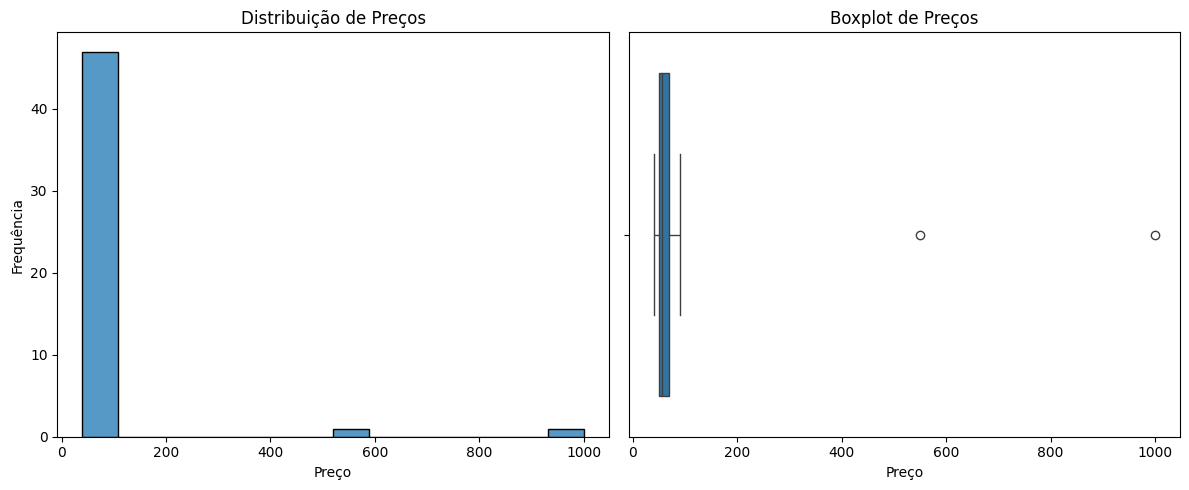

In [15]:
fig, axes = plt.subplots (1,2,figsize=(12, 5))

sns.histplot(data=df, x="preco", ax=axes[0])
axes[0].set_title("Distribuição de Preços")
axes[0].set_xlabel("Preço")
axes[0].set_ylabel("Frequência")

sns.boxplot(data=df, x="preco", ax=axes[1])
axes[1].set_title("Boxplot de Preços")
axes[1].set_xlabel("Preço")

plt.tight_layout()
plt.show()


In [16]:
# Identificar possíveis outliers com base no IQR

q1 = df["preco"].quantile(0.25)
q3 = df["preco"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

precos_suspeitos = df.loc[
    (df["preco"] < limite_inferior) | (df["preco"] > limite_superior),
    ["id_livro", "titulo", "preco", "categoria"]
]

print(f"Q1: {q1:.2f}, Q3: {q3:.2f}, IQR: {iqr:.2f}")
print(f"Limites: Inferior = {limite_inferior:.2f}, Superior = {limite_superior:.2f}")
print(f"Número de preços suspeitos: {len(precos_suspeitos)}")

display(precos_suspeitos)

Q1: 49.90, Q3: 69.90, IQR: 20.00
Limites: Inferior = 19.90, Superior = 99.90
Número de preços suspeitos: 2


,id_livro,titulo,preco,categoria
34,35,O Investidor Inteligente,999.9,Financeiro
41,42,A Vida Mentirosa dos Adultos,549.0,Drama


---

## 8. Relatório automatizado com ydata-profiling (Pandas Profiling)

In [17]:
from ydata_profiling import ProfileReport

# Para uma AED, gerar o relatório com a cópia de trabalho já tipada
profile = ProfileReport(
    df,
    title="Relatório de AED — Catálogo de Livros",
    explorative=True,
    minimal=False
)

arquivo_relatorio = "relatorio_aed_livros.html"
profile.to_file(arquivo_relatorio)
print(f"Relatório salvo em: {arquivo_relatorio}")

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 111.42it/s]

Relatório salvo em: relatorio_aed_livros.html


In [18]:
%pip install -q ydata-profiling pandas matplotlib seaborn sweetviz

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
%pip install "setuptools<81

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 9. Automatizando relatório com Sweetviz

In [22]:
import sweetviz as sv

# O Sweetviz não lida bem com pd.NA em alguns tipos anuláveis do pandas.
# Adaptamos uma cópia para o relatório e preservamos df sem alterações.
df_sweetviz = df.copy()

for coluna in df_sweetviz.columns:
    tipo = df_sweetviz[coluna].dtype

    if isinstance(tipo, pd.StringDtype) or pd.api.types.is_object_dtype(tipo):
        serie = df_sweetviz[coluna]
        df_sweetviz[coluna] = serie.astype(object).where(serie.notna(), None)
    elif pd.api.types.is_numeric_dtype(tipo) and pd.api.types.is_extension_array_dtype(tipo):
        if pd.api.types.is_integer_dtype(tipo) and not df_sweetviz[coluna].isna().any():
            df_sweetviz[coluna] = df_sweetviz[coluna].astype("int64")
        else:
            df_sweetviz[coluna] = df_sweetviz[coluna].astype("float64")

relatorio_sv = sv.analyze(df_sweetviz)
relatorio_sv.show_html("relatorio_sweetviz_livros.html", open_browser=True)

print("Relatório Sweetviz salvo em: relatorio_sweetviz_livros.html")

Done! Use 'show' commands to display/save.   |██████████| [100%]   00:00 -> (00:00 left)


Report relatorio_sweetviz_livros.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.
Relatório Sweetviz salvo em: relatorio_sweetviz_livros.html
